Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

--- Entrenando Dual-Stream RNN (Optimizado para Velocidad y QAM) ---
Epoch 1/60
263/263 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.4610 - loss: 1.3727 - val_accuracy: 0.6754 - val_loss: 0.7344 - learning_rate: 0.0010
Epoch 2/60
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.6823 - loss: 0.6617 - val_accuracy: 0.7176 - val_loss: 0.5484 - learning_rate: 0.0010
Epoch 3/60
263/263 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.7189 - loss: 0.5406 - val_accuracy: 0.7422 - val_loss: 0.4978 - learning_rate: 0.0010
Epoch 4/60
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.7408 - loss: 0.5086 - val_accuracy: 0.7540 - val_loss: 0.4891 - learning_rate: 0.0010
Epoch 5/60
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.7587 - loss: 0.4676 - val_accuracy: 0.7663 - val_loss: 0.4548 - learning_rate: 0.0010
Epoch 6/60
263/263 ━━━━━━━━━━━━━━━━━

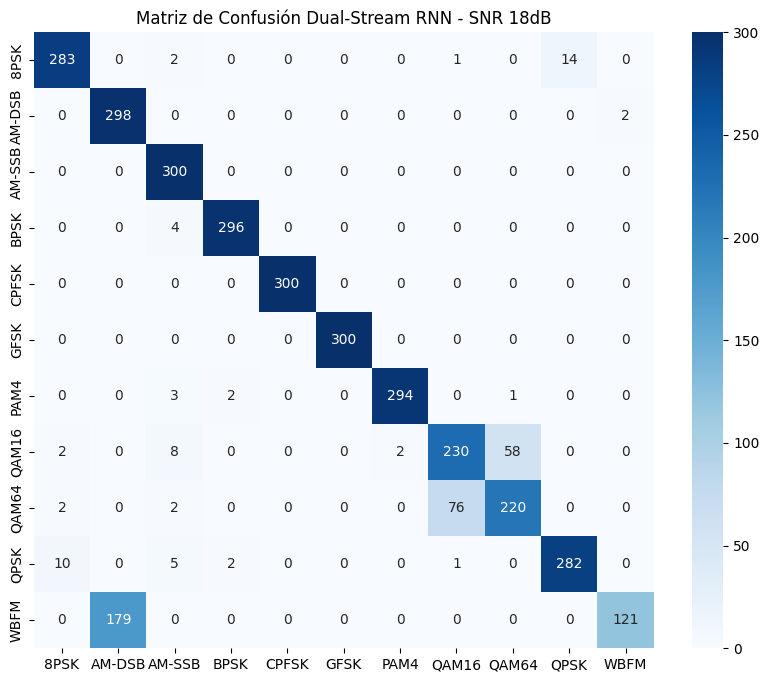

              precision    recall  f1-score   support

        8PSK       0.95      0.94      0.95       300
      AM-DSB       0.62      0.99      0.77       300
      AM-SSB       0.93      1.00      0.96       300
        BPSK       0.99      0.99      0.99       300
       CPFSK       1.00      1.00      1.00       300
        GFSK       1.00      1.00      1.00       300
        PAM4       0.99      0.98      0.99       300
       QAM16       0.75      0.77      0.76       300
       QAM64       0.79      0.73      0.76       300
        QPSK       0.95      0.94      0.95       300
        WBFM       0.98      0.40      0.57       300

    accuracy                           0.89      3300
   macro avg       0.91      0.89      0.88      3300
weighted avg       0.91      0.89      0.88      3300



In [ ]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# 1. CARGA DE DATOS
drive.mount('/content/drive')
FILE_PATH = '/content/drive/MyDrive/Seminario/RML2016.10a_dict.pkl'

with open(FILE_PATH, 'rb') as f:
    dataset = pickle.load(f, encoding='latin1')

mods, _ = map(lambda x: sorted(list(set(x))), zip(*dataset.keys()))

# 2. PROCESAMIENTO DUAL-STREAM (Más rápido y eficiente)
def preparar_datos_dual(snr_target):
    X_list, y_list = [], []
    # Entrenar con el target y uno ligeramente inferior para dar contexto
    target_snrs = [snr_target - 2, snr_target]

    for mod in mods:
        for s in target_snrs:
            if (mod, s) in dataset:
                data = dataset[(mod, s)]
                X_list.append(data)
                y_list.extend([mod] * data.shape[0])

    X = np.transpose(np.vstack(X_list), (0, 2, 1))

    # Normalización por el máximo absoluto (Preserva mejor los niveles QAM que L2)
    X /= (np.max(np.abs(X), axis=(1, 2), keepdims=True) + 1e-8)

    I, Q = X[:,:,0], X[:,:,1]
    A = np.sqrt(I**2 + Q**2)
    P = np.arctan2(Q, I)

    # Stream 1: Info de Amplitud (Para QAM/PAM)
    X_amp = np.stack([A, np.gradient(A, axis=1)], axis=-1)
    # Stream 2: Info de Fase/IQ (Para PSK/FM)
    X_phase = np.stack([I, Q, P], axis=-1)

    return X_amp, X_phase, np.array(y_list)

# 3. MODELO DUAL-STREAM RNN
def crear_modelo_dual(shape_amp, shape_phase, num_classes):
    # Rama de Amplitud
    input_amp = layers.Input(shape=shape_amp)
    a = layers.GRU(64, return_sequences=True)(input_amp) # GRU es más rápida que LSTM
    a = layers.GlobalMaxPooling1D()(a)

    # Rama de Fase
    input_phase = layers.Input(shape=shape_phase)
    p = layers.Bidirectional(layers.GRU(64, return_sequences=True))(input_phase)
    p = layers.GlobalAveragePooling1D()(p)

    # Fusión
    concat = layers.Concatenate()([a, p])

    # Cabeza densa optimizada
    x = layers.Dense(128, activation='relu')(concat)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs=[input_amp, input_phase], outputs=outputs)

    # Subimos el LR inicial para romper el estancamiento de 83%
    opt = tf.keras.optimizers.Adam(learning_rate=0.001)
    model.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# --- EJECUCIÓN ---
SNR_VAL = 18
X_a, X_p, y = preparar_datos_dual(SNR_VAL)
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Split alineado
indices = np.arange(len(y_encoded))
train_idx, test_idx = train_test_split(indices, test_size=0.15, stratify=y_encoded, random_state=42)

model = crear_modelo_dual((128, 2), (128, 3), len(mods))

# Callbacks: Reducción de LR agresiva si se estanca
callbacks_list = [
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=4, verbose=1),
    callbacks.EarlyStopping(monitor='val_accuracy', patience=12, restore_best_weights=True)
]

print("\n--- Entrenando Dual-Stream RNN (Optimizado para Velocidad y QAM) ---")
model.fit([X_a[train_idx], X_p[train_idx]], y_encoded[train_idx],
          epochs=60, # No necesitamos 100 con esta estructura
          batch_size=64,
          validation_split=0.1,
          callbacks=callbacks_list)

# --- RESULTADOS Y MATRIZ ---
y_pred = np.argmax(model.predict([X_a[test_idx], X_p[test_idx]]), axis=1)
cm = confusion_matrix(y_encoded[test_idx], y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=mods, yticklabels=mods, cmap='Blues')
plt.title(f'Matriz de Confusión Dual-Stream RNN - SNR {SNR_VAL}dB')
plt.show()

print(classification_report(y_encoded[test_idx], y_pred, target_names=mods))